<a href="https://colab.research.google.com/github/aniketsable586-ops/Project-3/blob/main/Project3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

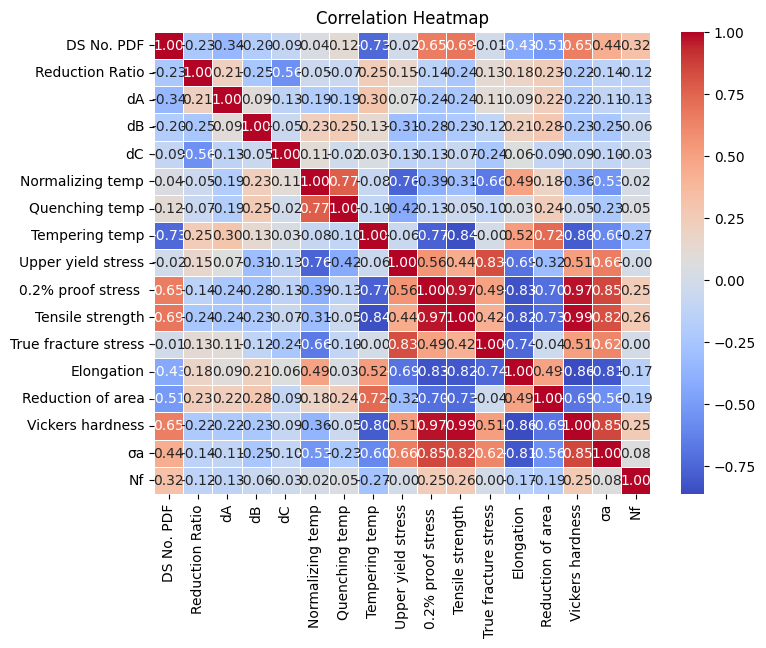

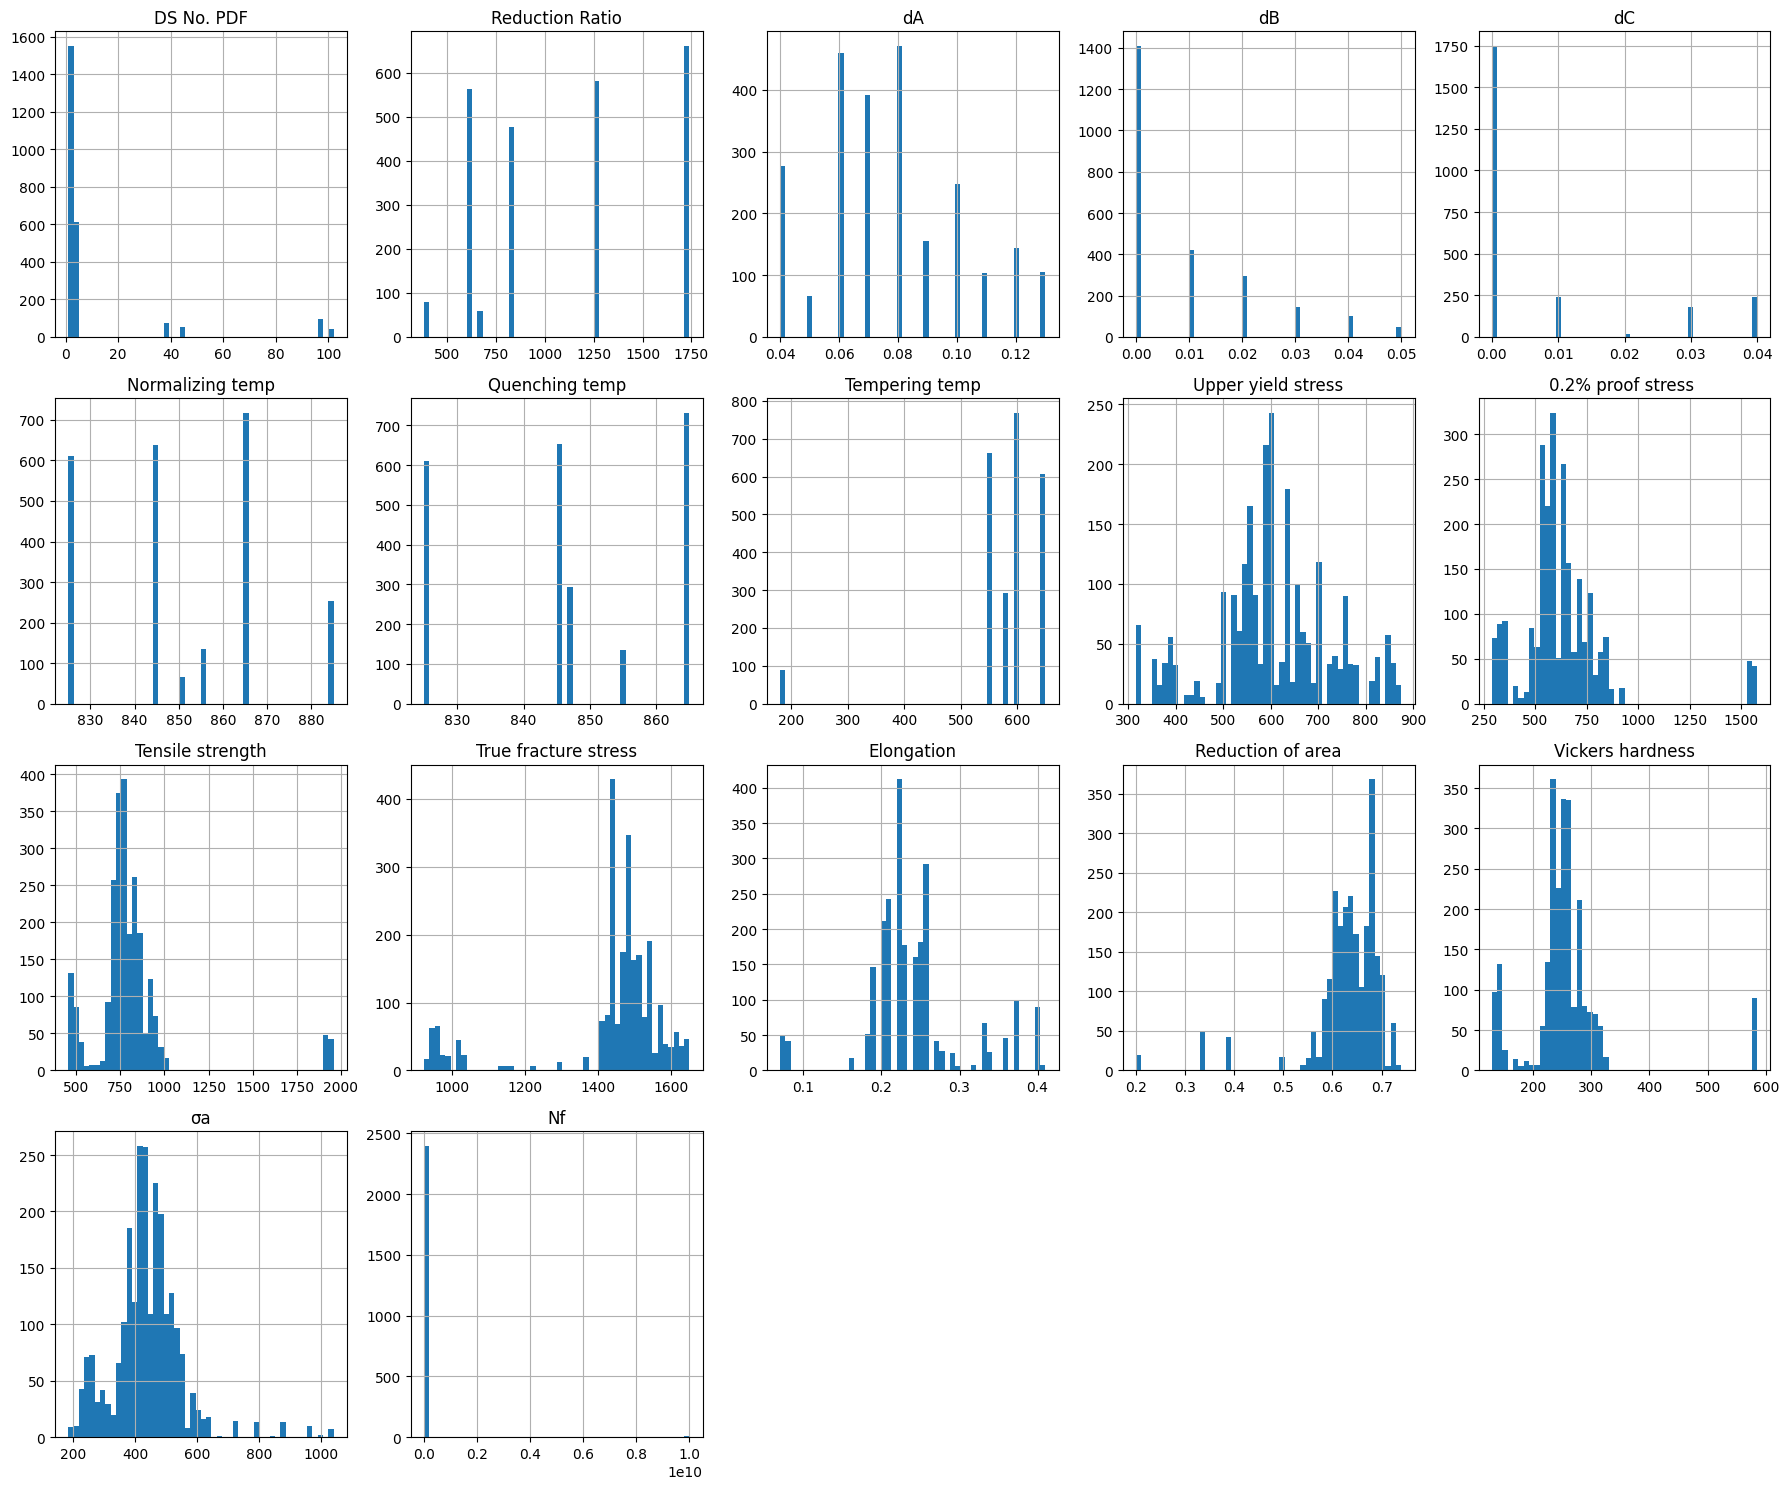

Dataset size after removing outliers >= 10000000: 1975 rows
X_train shape: (1580, 17)
X_test shape:  (395, 17)

--- Base XGBoost Model ---
Raw R-squared (R²):   0.23
Log10 MAE:            0.189 (orders of magnitude)
Log10 R-squared (R²): 0.70

Searching for the best hyperparameters. This may take a minute...

--- Tuned XGBoost Evaluation ---
Best Parameters:      {'regressor__subsample': 1.0, 'regressor__n_estimators': 1000, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.01, 'regressor__colsample_bytree': 0.8}
Raw R-squared (R²):   0.46
Log10 MAE:            0.189
Log10 R-squared (R²): 0.75


In [2]:
# ==============================================================================
# Project 3: Machine Learning for Fatigue Lifetime Prediction of Structural Steels
# ==============================================================================

# %% 1. Imports & Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor


# %% 2. Data Loading & Cleaning
df = pd.read_excel('NIMS_FATIGUE.xlsx')

# Impute missing values with column means
cols_to_impute = [
    "Quenching temp",
    "Tempering temp",
    "Normalizing temp",
    "Upper yield stress",
    "True fracture stress"
]

for col in cols_to_impute:
    df[col] = df[col].fillna(df[col].mean())

# Remove duplicate rows
df.drop_duplicates(inplace=True)


# %% 3. Exploratory Data Analysis (EDA)
# Correlation Heatmap
plt.figure(figsize=(8, 6))
matrix = df.corr(numeric_only=True)
sns.heatmap(matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

# Feature Distributions
df.hist(figsize=(18, 15), bins=50, layout=(4, 5))
plt.tight_layout()
plt.show()


# %% 4. Feature Selection, Outlier Filtering & Engineering
# Drop redundant columns identified from the correlation matrix
cols_to_drop = ['Heat', 'DS No. PDF', '0.2% proof stress ', 'Vickers hardness']
df = df.drop(columns=cols_to_drop)

# Filter out runouts and extreme outliers
threshold = 10_000_000
df = df[df['Nf'] < threshold].copy()
print(f"Dataset size after removing outliers >= {threshold}: {len(df)} rows")

# Feature Engineering
df['Stress_Ratio'] = df['σa'] / df['Tensile strength']
df['Log_σa'] = np.log10(df['σa'])


# %% 5. Train-Test Split & Preprocessing
X = df.drop('Nf', axis=1)
y = df['Nf']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")

# One-hot encode categorical columns while keeping numeric columns untouched
categorical_cols = ['Testing Material', 'Type of test']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(sparse_output=False), categorical_cols)
    ],
    remainder='passthrough'
).set_output(transform="pandas")

X_train_final = preprocessor.fit_transform(X_train)
X_test_final = preprocessor.transform(X_test)


# %% 6. Base XGBoost Model & Evaluation
# Initialize and wrap XGBoost with log-target transformation
base_xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)

log_xgb_model = TransformedTargetRegressor(
    regressor=base_xgb,
    func=np.log1p,
    inverse_func=np.expm1
)

# Train and predict
log_xgb_model.fit(X_train_final, y_train)
y_pred_raw = log_xgb_model.predict(X_test_final)

# Engineering Evaluation (Base-10 Log for fatigue life scoring)
y_test_log10 = np.log10(y_test)
y_pred_log10 = np.log10(y_pred_raw)

print("\n--- Base XGBoost Model ---")
print(f"Raw R-squared (R²):   {r2_score(y_test, y_pred_raw):.2f}")
print(f"Log10 MAE:            {mean_absolute_error(y_test_log10, y_pred_log10):.3f} (orders of magnitude)")
print(f"Log10 R-squared (R²): {r2_score(y_test_log10, y_pred_log10):.2f}")


# %% 7. Hyperparameter Tuning & Final Evaluation
param_distributions = {
    'regressor__n_estimators': [300, 500, 1000],
    'regressor__learning_rate': [0.01, 0.05, 0.1],
    'regressor__max_depth': [4, 6, 8, 10],
    'regressor__subsample': [0.7, 0.8, 1.0],
    'regressor__colsample_bytree': [0.7, 0.8, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=log_xgb_model,
    param_distributions=param_distributions,
    n_iter=20,
    cv=5,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

print("\nSearching for the best hyperparameters. This may take a minute...")
random_search.fit(X_train_final, y_train)

# Evaluate best model
best_model = random_search.best_estimator_
y_pred_best = best_model.predict(X_test_final)
y_pred_best_log10 = np.log10(y_pred_best)

print("\n--- Tuned XGBoost Evaluation ---")
print(f"Best Parameters:      {random_search.best_params_}")
print(f"Raw R-squared (R²):   {r2_score(y_test, y_pred_best):.2f}")
print(f"Log10 MAE:            {mean_absolute_error(y_test_log10, y_pred_best_log10):.3f}")
print(f"Log10 R-squared (R²): {r2_score(y_test_log10, y_pred_best_log10):.2f}")









